# 02 - Preprocessing: Penandaan Nilai Hilang dan Penggabungan Pima + GDM

Notebook ini menandai nilai hilang pada kedua dataset (mengikuti
konvensi masing-masing), menyelaraskan nama kolom, lalu menggabungkan
keduanya menjadi satu dataset dengan target `DiagnosisType` 3 kelas
berbasis diagnosis asli.

Nilai hilang **sengaja belum diisi di sini**. Pengisian dilakukan pada
`03_GaussianNB` setelah data dibagi latih/uji, memakai median data
latih tanpa melihat label -- alasannya pada bagian 2.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_PATH = PROJECT_ROOT / "data" / "diabetes.csv"
GDM_PATH = PROJECT_ROOT / "data" / "gdm_dataset.xlsx"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Bentuk data yang diasumsikan seluruh notebook. Dicek saat memuat agar
# berkas yang salah langsung ketahuan, bukan diam-diam ikut dipakai.
PIMA_COLUMNS = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
    "BMI", "DiabetesPedigreeFunction", "Age", "Outcome",
]
PIMA_SHAPE = (768, 9)
GDM_SHEET_NAME = "GDM-Final2022"
GDM_SHAPE = (3525, 17)
CLASS_COL = "Class Label(GDM /Non GDM)"

# Kolom fisiologis Pima yang nilai 0-nya berarti data hilang, bukan
# hasil pengukuran.
ZERO_AS_MISSING_COLUMNS = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Kolom GDM yang punya padanan konsep langsung di Pima -> nama kolom Pima.
# Hanya lima inilah yang dipakai bersama pada model gabungan.
GDM_TO_PIMA_COLUMNS = {
    "Age": "Age",
    "No of Pregnancy": "Pregnancies",
    "BMI": "BMI",
    "Dia BP": "BloodPressure",
    "OGTT": "Glucose",
}

SHARED_FEATURES = list(GDM_TO_PIMA_COLUMNS.values())
DIAGNOSIS_LABELS = ["Normal", "Tipe 2", "Gestasional"]

df_pima = pd.read_csv(DATA_PATH)
df_gdm = pd.read_excel(GDM_PATH, sheet_name=GDM_SHEET_NAME)
assert list(df_pima.columns) == PIMA_COLUMNS, f"Kolom Pima tidak sesuai: {list(df_pima.columns)}"
assert df_pima.shape == PIMA_SHAPE, f"Bentuk data Pima tidak sesuai: {df_pima.shape}"
assert df_gdm.shape == GDM_SHAPE, f"Bentuk data GDM tidak sesuai: {df_gdm.shape}"
print(f"Pima: {df_pima.shape} | GDM: {df_gdm.shape}")

Pima: (768, 9) | GDM: (3525, 17)


## 1. Tandai Nilai Hilang Pima

Nilai 0 pada lima kolom fisiologis Pima bukan hasil pengukuran,
melainkan penanda data hilang -- diganti `NaN`. Dari lima kolom itu
hanya tiga yang dipakai model gabungan: `Glucose`, `BloodPressure`,
dan `BMI`.

In [2]:
df_pima_ditandai = df_pima.copy()
df_pima_ditandai[ZERO_AS_MISSING_COLUMNS] = df_pima_ditandai[ZERO_AS_MISSING_COLUMNS].replace(0, np.nan)

print("Nilai hilang Pima pada lima fitur bersama:")
print(df_pima_ditandai[SHARED_FEATURES].isna().sum().to_string())

Nilai hilang Pima pada lima fitur bersama:
Age               0
Pregnancies       0
BMI              11
BloodPressure    35
Glucose           5


## 2. Nilai Hilang GDM dan Alasan Imputasi Ditunda

GDM sudah memakai `NaN` eksplisit (bukan sentinel 0), sehingga tidak
perlu langkah "tandai nilai 0". Hanya `BMI` dan `OGTT` yang punya nilai
hilang di antara lima kolom yang dipakai bersama Pima.

Revisi sebelumnya mengisi nilai hilang dengan **median per kelas
diagnosis, sebelum data dibagi latih/uji**. Cara itu membocorkan
label: seluruh nilai hilang GDM ada pada kelas Non-GDM (sel di bawah),
sehingga nilai pengisinya langsung menandai kelas baris tersebut --
termasuk baris yang nantinya masuk data uji. Karena itu imputasi
dipindah ke `03_GaussianNB`: dilakukan **setelah** split, memakai
median **data latih** tanpa melihat label. Dampak perubahan ini diukur
pada `04_Evaluation`.

In [3]:
hilang_per_kelas = df_gdm[["BMI", "OGTT"]].isna().groupby(df_gdm[CLASS_COL]).sum()
hilang_per_kelas["jumlah_pasien"] = df_gdm.groupby(CLASS_COL).size()
hilang_per_kelas

,BMI,OGTT,jumlah_pasien
Class Label(GDM /Non GDM),,,
0,1081,513,2153
1,0,0,1372


## 3. Harmonisasi Nama Kolom GDM

Hanya lima kolom yang berpadanan dengan Pima (plus label kelas) yang
diambil, lalu namanya disamakan dengan nama kolom Pima.

In [4]:
df_gdm_harmon = df_gdm[list(GDM_TO_PIMA_COLUMNS) + [CLASS_COL]].rename(columns=GDM_TO_PIMA_COLUMNS)
df_gdm_harmon.head()

,Age,Pregnancies,BMI,BloodPressure,Glucose,Class Label(GDM /Non GDM)
0,22,2,NaN,69,NaN,0
1,26,2,NaN,63,NaN,0
2,29,1,NaN,79,NaN,0
3,28,2,NaN,70,NaN,0
4,21,2,NaN,65,NaN,0


## 4. Bangun Label DiagnosisType dan Gabungkan

- Pima: `Outcome=0` -> `Normal`, `Outcome=1` -> `Tipe 2`
- GDM: `Class=0` -> `Normal`, `Class=1` -> `Gestasional`


In [5]:
pima_portion = df_pima_ditandai[SHARED_FEATURES].copy()
pima_portion["DiagnosisType"] = np.where(df_pima_ditandai["Outcome"] == 1, "Tipe 2", "Normal")
pima_portion["SumberData"] = "Pima"

gdm_portion = df_gdm_harmon[SHARED_FEATURES].copy()
gdm_portion["DiagnosisType"] = np.where(df_gdm_harmon[CLASS_COL] == 1, "Gestasional", "Normal")
gdm_portion["SumberData"] = "GDM"

print("Pima portion:", pima_portion.shape, "| kolom:", list(pima_portion.columns))
print("GDM portion :", gdm_portion.shape, "| kolom:", list(gdm_portion.columns))

# Kolom sudah identik di kedua sisi, jadi ini murni penggabungan baris
# (tidak ada pasien yang sama di kedua studi).
gabungan = pd.concat([pima_portion, gdm_portion], ignore_index=True)
print()
print(f"Dataset gabungan: {gabungan.shape}")
print()
print("Distribusi DiagnosisType:")
print(gabungan["DiagnosisType"].value_counts().reindex(DIAGNOSIS_LABELS))
print()
print("Distribusi berdasarkan DiagnosisType x SumberData:")
print(pd.crosstab(gabungan["DiagnosisType"], gabungan["SumberData"]))
print()
print("Nilai hilang pada dataset gabungan (diisi nanti, setelah split):")
print(gabungan[SHARED_FEATURES].isna().sum().to_string())

Pima portion: (768, 7) | kolom: ['Age', 'Pregnancies', 'BMI', 'BloodPressure', 'Glucose', 'DiagnosisType', 'SumberData']
GDM portion : (3525, 7) | kolom: ['Age', 'Pregnancies', 'BMI', 'BloodPressure', 'Glucose', 'DiagnosisType', 'SumberData']

Dataset gabungan: (4293, 7)

Distribusi DiagnosisType:
DiagnosisType
Normal         2653
Tipe 2          268
Gestasional    1372
Name: count, dtype: int64

Distribusi berdasarkan DiagnosisType x SumberData:
SumberData      GDM  Pima
DiagnosisType            
Gestasional    1372     0
Normal         2153   500
Tipe 2            0   268

Nilai hilang pada dataset gabungan (diisi nanti, setelah split):
Age                 0
Pregnancies         0
BMI              1092
BloodPressure      35
Glucose           518


Perhatikan: `Tipe 2` hanya berasal dari Pima, `Gestasional` hanya dari
GDM -- `SumberData` secara struktural berkorelasi dengan
`DiagnosisType` (bukan perfect predictor, karena `Normal` muncul di
keduanya, tetapi tetap berkorelasi kuat). Ini bagian dari keterbatasan
yang sama dibahas pada `01_EDA` bagian 7, dan dibuktikan dampaknya pada
`04_Evaluation`.


## 5. Visualisasi Distribusi Fitur Gabungan per Kelas

Hanya nilai yang benar-benar teramati -- nilai hilang belum diisi.

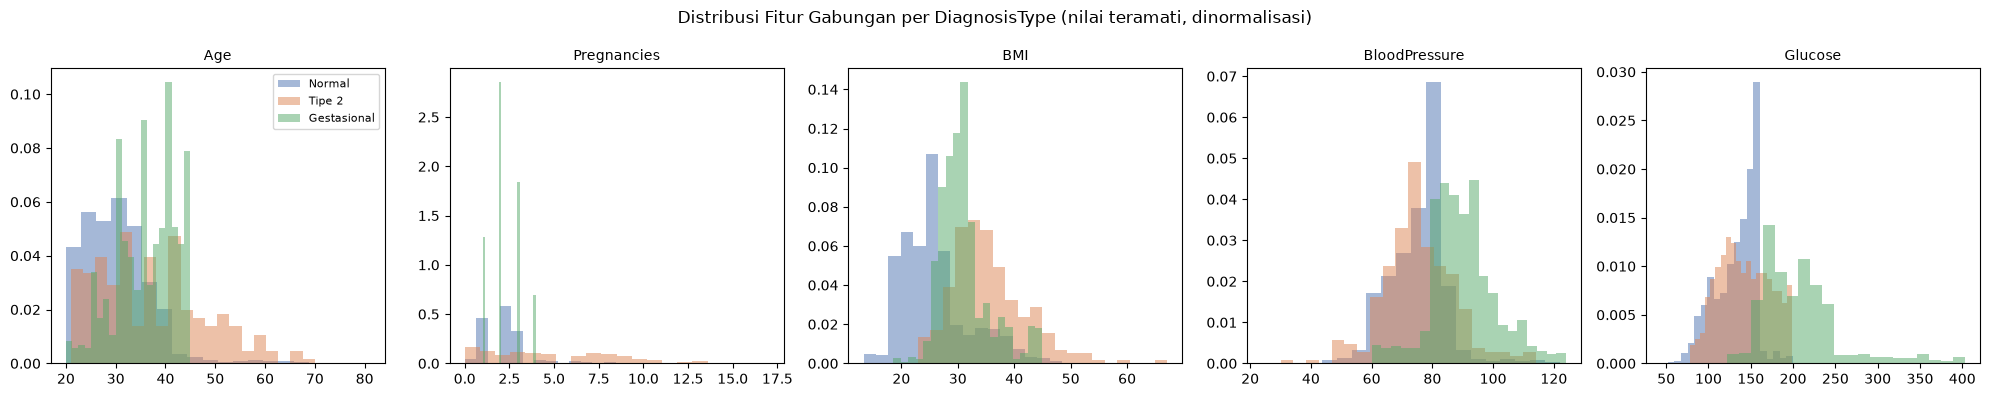

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, kolom in zip(axes, SHARED_FEATURES):
    for kelas, warna in zip(DIAGNOSIS_LABELS, ["#4C72B0", "#DD8452", "#55A868"]):
        data = gabungan.loc[gabungan["DiagnosisType"] == kelas, kolom].dropna()
        ax.hist(data, bins=20, alpha=0.5, color=warna, label=kelas, density=True)
    ax.set_title(kolom, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Distribusi Fitur Gabungan per DiagnosisType (nilai teramati, dinormalisasi)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "preprocessing_merged_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

`BMI` menunjukkan pemisahan yang mencurigakan rapi antara kelompok
Pima (`Normal`, `Tipe 2`) vs GDM (`Gestasional`) -- konsisten dengan
temuan `01_EDA` bahwa ini sebagian mencerminkan perbedaan sumber data,
bukan murni tipe diabetes.


## 6. Simpan Dataset Gabungan


In [7]:
output_path = PROCESSED_DIR / "merged_diagnosis.csv"
gabungan.to_csv(output_path, index=False)
print(f"Tersimpan: {output_path} ({gabungan.shape[0]} baris, {gabungan.shape[1]} kolom)")


Tersimpan: D:\diabetes-risk-gnb\data\processed\merged_diagnosis.csv (4293 baris, 7 kolom)


**Lanjut ke `03_GaussianNB.ipynb`** untuk pembagian data latih/uji,
imputasi median data latih, dan pelatihan model Gaussian Naive Bayes
memakai target `DiagnosisType`.